> Repository edition: run from the repository root using an environment with the dependencies in `requirements.txt`. Machine-specific environment paths have been replaced. Historical outputs are retained except environment checks; they are not evidence of a fresh rerun. See `docs/REPRODUCIBILITY.md`.


# CP_25 — Final evaluation and retrospective

This notebook evaluates the completed black-box optimisation project using
the initial observations and feedback from all thirteen submission rounds.

The analysis covers eight functions with different input dimensions and
output scales. It validates the cumulative observations, compares the
final-round outcomes with the predictions recorded in CP_24, and tracks
the best observed output for each function throughout the project.

The results will support the Module 25 retrospective, the discussion of
successful strategies, and the final repository documentation.

No further queries are generated. Predictions are kept separate from
observed outcomes, and improvements are assessed within each function.

## 1. Check the environment and locate the final feedback

The project uses the same Python environment and directory structure as
the preceding notebooks. The `week_13` folder contains the cumulative
feedback files for all thirteen completed rounds.

In [ ]:
# CP_25 — Final evaluation
# Check the Python environment and locate the project data.

import sys
from pathlib import Path

project_path = Path.cwd()

# Use the selected notebook kernel; no machine-specific path is required.
expected_python = Path(sys.executable)

initial_data_path = project_path / "initial_data"
feedback_path = project_path / "week_13"

inputs_path = feedback_path / "inputs.txt"
outputs_path = feedback_path / "outputs.txt"
previous_notebook_path = project_path / "CP_24.ipynb"

# File contents will be validated in the next section.
completed_rounds = 13
expected_total_observations = 175 + completed_rounds * 8

correct_kernel = (
    Path(sys.executable).resolve() == expected_python.resolve()
)

print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())
print("Project folder:", project_path)

print("\nSelected interpreter check:", correct_kernel)
print("Project folder found:", project_path.is_dir())
print("Initial data folder found:", initial_data_path.is_dir())
print("Feedback folder found:", feedback_path.is_dir())
print("Cumulative inputs found:", inputs_path.is_file())
print("Cumulative outputs found:", outputs_path.is_file())
print("CP_24 notebook found:", previous_notebook_path.is_file())

print("\nExpected completed rounds:", completed_rounds)
print("Expected total observations:", expected_total_observations)
print("Analysis stage: final evaluation; no further queries.")

assert correct_kernel, (
    "Select the notebook kernel corresponding to: "
    f"{expected_python}"
)
assert project_path.is_dir(), (
    f"Project folder not found: {project_path}"
)
assert initial_data_path.is_dir(), (
    f"Initial data folder not found: {initial_data_path}"
)
assert feedback_path.is_dir(), (
    f"Feedback folder not found: {feedback_path}"
)
assert inputs_path.is_file(), (
    f"Inputs file not found: {inputs_path}"
)
assert outputs_path.is_file(), (
    f"Outputs file not found: {outputs_path}"
)
assert previous_notebook_path.is_file(), (
    f"Previous notebook not found: {previous_notebook_path}"
)

import numpy as np
import pandas as pd
from IPython.display import display

print("\nEnvironment and file checks passed.")
print(
    f"Ready to load and validate the {completed_rounds} feedback rounds."
)

## 2. Load and validate the final cumulative observations

The initial observations are combined with thirteen completed feedback
rounds for each of the eight functions, giving 279 evaluated input–output
pairs in total.

Validation checks the number of rounds, input dimensions, finite
numerical values and input bounds. Negative and extremely small outputs
are retained without modification.

The cumulative feedback files are loaded once. Earlier weekly snapshots
are not appended again, avoiding duplicate counting of evaluations.
Rerunning this cell rebuilds the datasets from their source files.

This notebook evaluates the completed project; no further queries are
generated.

In [2]:
# CP_25 — Final evaluation
# Load and validate the initial observations and all 13 feedback rounds.

import ast
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "initial_data_path",
    "inputs_path",
    "outputs_path",
    "completed_rounds",
    "expected_total_observations",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the environment-check cell first. Missing variables: "
        + ", ".join(missing_variables)
    )

if completed_rounds != 13:
    raise ValueError("Final evaluation requires exactly 13 feedback rounds.")


def parse_numeric_expression(node):
    """Read numeric literals, lists and array wrappers without eval."""
    if isinstance(node, ast.Constant):
        if isinstance(node.value, (int, float)) and not isinstance(
            node.value, bool
        ):
            return node.value
        raise ValueError("Only numerical constants are permitted.")

    if isinstance(node, (ast.List, ast.Tuple)):
        return [parse_numeric_expression(item) for item in node.elts]

    if isinstance(node, ast.UnaryOp) and isinstance(
        node.op, (ast.UAdd, ast.USub)
    ):
        value = parse_numeric_expression(node.operand)
        if not isinstance(value, (int, float)):
            raise ValueError("A sign must precede a numerical value.")
        return value if isinstance(node.op, ast.UAdd) else -value

    if isinstance(node, ast.Call):
        function = node.func

        allowed_array = (
            isinstance(function, ast.Name)
            and function.id == "array"
        ) or (
            isinstance(function, ast.Attribute)
            and isinstance(function.value, ast.Name)
            and function.value.id in {"np", "numpy"}
            and function.attr == "array"
        )

        if allowed_array and len(node.args) == 1 and not node.keywords:
            return parse_numeric_expression(node.args[0])

    raise ValueError(
        "Unsupported expression in feedback file: "
        + ast.dump(node, include_attributes=False)[:160]
    )


def read_feedback_rounds(path, expected_rounds):
    """Read separate round lists or one outer list containing all rounds."""
    path = Path(path)
    text = path.read_text(encoding="utf-8-sig").strip()

    if not text:
        raise ValueError(f"Feedback file is empty: {path}")

    try:
        tree = ast.parse(text, mode="exec")
    except SyntaxError as error:
        raise ValueError(
            f"Unable to parse feedback file: {path.name}. "
            "Keep its original numerical list format."
        ) from error

    values = []

    for statement in tree.body:
        if not isinstance(statement, ast.Expr):
            raise ValueError(
                f"Unexpected statement in {path.name}; "
                "only numerical round lists are permitted."
            )

        values.append(parse_numeric_expression(statement.value))

    # Accept separate round lists or a single outer list of rounds.
    if (
        len(values) == 1
        and isinstance(values[0], list)
        and len(values[0]) == expected_rounds
        and all(
            isinstance(item, list) and len(item) == 8
            for item in values[0]
        )
    ):
        values = values[0]

    if len(values) != expected_rounds:
        raise ValueError(
            f"{path.name}: expected {expected_rounds} rounds, "
            f"found {len(values)}."
        )

    for round_number, round_values in enumerate(values, start=1):
        if not isinstance(round_values, list) or len(round_values) != 8:
            raise ValueError(
                f"{path.name}, round {round_number}: "
                "expected exactly eight function entries."
            )

    return values


function_dimensions = {
    1: 2,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 5,
    7: 6,
    8: 8,
}

expected_initial_counts = {
    1: 10,
    2: 10,
    3: 15,
    4: 30,
    5: 20,
    6: 20,
    7: 30,
    8: 40,
}

input_rounds = read_feedback_rounds(inputs_path, completed_rounds)
output_rounds = read_feedback_rounds(outputs_path, completed_rounds)

# Rebuild from source files so rerunning cannot append data twice.
initial_data = {}
feedback_data = {}
updated_data = {}
validation_records = []

for function_id in range(1, 9):
    dimensions = function_dimensions[function_id]
    expected_initial = expected_initial_counts[function_id]

    function_folder = (
        Path(initial_data_path) / f"function_{function_id}"
    )
    initial_inputs_file = function_folder / "initial_inputs.npy"
    initial_outputs_file = function_folder / "initial_outputs.npy"

    for file_path in [initial_inputs_file, initial_outputs_file]:
        if not file_path.is_file():
            raise FileNotFoundError(f"Required file not found: {file_path}")

    X_initial = np.asarray(
        np.load(initial_inputs_file, allow_pickle=False),
        dtype=float,
    )
    y_initial_raw = np.asarray(
        np.load(initial_outputs_file, allow_pickle=False),
        dtype=float,
    )

    if X_initial.shape != (expected_initial, dimensions):
        raise ValueError(
            f"Function {function_id}: initial input shape "
            f"{X_initial.shape}; expected "
            f"({expected_initial}, {dimensions})."
        )

    if y_initial_raw.shape not in {
        (expected_initial,),
        (expected_initial, 1),
    }:
        raise ValueError(
            f"Function {function_id}: unexpected initial output shape "
            f"{y_initial_raw.shape}."
        )

    y_initial = y_initial_raw.reshape(-1)

    function_inputs = []
    function_outputs = []

    for round_index in range(completed_rounds):
        query = np.asarray(
            input_rounds[round_index][function_id - 1],
            dtype=float,
        )
        output = np.asarray(
            output_rounds[round_index][function_id - 1],
            dtype=float,
        )

        if query.shape != (dimensions,):
            raise ValueError(
                f"Function {function_id}, round {round_index + 1}: "
                f"input shape {query.shape}; expected ({dimensions},)."
            )

        if output.size != 1:
            raise ValueError(
                f"Function {function_id}, round {round_index + 1}: "
                "expected one scalar output."
            )

        function_inputs.append(query)
        function_outputs.append(float(output.reshape(-1)[0]))

    X_feedback = np.vstack(function_inputs)
    y_feedback = np.asarray(function_outputs, dtype=float)

    X_all = np.vstack([X_initial, X_feedback])
    y_all = np.concatenate([y_initial, y_feedback])

    if not np.all(np.isfinite(X_all)):
        raise ValueError(
            f"Function {function_id}: non-finite input coordinates."
        )

    if not np.all(np.isfinite(y_all)):
        raise ValueError(
            f"Function {function_id}: non-finite observed outputs."
        )

    # Validate historical inputs against the unit-cube domain.
    if np.any(X_all < 0.0) or np.any(X_all > 1.0):
        raise ValueError(
            f"Function {function_id}: historical inputs outside [0, 1]."
        )

    expected_total = expected_initial + completed_rounds

    if X_all.shape != (expected_total, dimensions):
        raise ValueError(
            f"Function {function_id}: incorrect cumulative input shape."
        )

    if y_all.shape != (expected_total,):
        raise ValueError(
            f"Function {function_id}: incorrect cumulative output shape."
        )

    initial_data[function_id] = {
        "X": X_initial.copy(),
        "y": y_initial.copy(),
    }
    feedback_data[function_id] = {
        "X": X_feedback.copy(),
        "y": y_feedback.copy(),
    }
    updated_data[function_id] = {
        "X": X_all.copy(),
        "y": y_all.copy(),
    }

    validation_records.append({
        "Function": function_id,
        "Initial observations": expected_initial,
        "Feedback observations": completed_rounds,
        "Total observations": len(y_all),
        "Dimensions": dimensions,
    })

    print(
        f"Function {function_id}: "
        f"{expected_initial} → {len(y_all)} observations "
        f"| {dimensions} variables"
    )

data_validation_df = (
    pd.DataFrame(validation_records)
    .set_index("Function")
)

total_observations = sum(
    len(dataset["y"]) for dataset in updated_data.values()
)

calculated_expected_total = (
    sum(expected_initial_counts.values()) + 8 * completed_rounds
)

if total_observations != calculated_expected_total:
    raise ValueError("Total observations do not match the round counts.")

if total_observations != expected_total_observations:
    raise ValueError(
        f"Expected {expected_total_observations} observations, "
        f"found {total_observations}."
    )

print(f"\nValidated feedback rounds: {completed_rounds}")
print(f"Total evaluated observations: {total_observations}")
print("Analysis stage: final evaluation; no further queries.")
print("All eight datasets loaded and validated successfully.")

Function 1: 10 → 23 observations | 2 variables
Function 2: 10 → 23 observations | 2 variables
Function 3: 15 → 28 observations | 3 variables
Function 4: 30 → 43 observations | 4 variables
Function 5: 20 → 33 observations | 4 variables
Function 6: 20 → 33 observations | 5 variables
Function 7: 30 → 43 observations | 6 variables
Function 8: 40 → 53 observations | 8 variables

Validated feedback rounds: 13
Total evaluated observations: 279
Analysis stage: final evaluation; no further queries.
All eight datasets loaded and validated successfully.


## 3. Evaluate the final round and overall progress

For each function, I compare the round-13 output with the best output
available before that evaluation. I also compare the final best observed
output with the initial best and record the rounds that improved it.

All eight functions are treated as maximisation problems. Improvements
are calculated from observed outputs, not predictions.

Output scales differ across functions, so raw improvements are reported
separately rather than combined into an overall score. These summaries
do not represent a leaderboard score or establish that a global optimum
has been found.

A round without improvement may still provide useful information about
the function or the limitations of the surrogate model.

In [3]:
# CP_25 — Final evaluation
# Summarise final-round outcomes and progress across all 13 rounds.

import numpy as np
import pandas as pd
from IPython.display import display

required_variables = [
    "initial_data",
    "feedback_data",
    "updated_data",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the data-loading cell first. Missing variables: "
        + ", ".join(missing_variables)
    )

if completed_rounds != 13:
    raise ValueError("This evaluation requires 13 completed rounds.")

final_round_records = []
overall_records = []
history_records = []
best_point_records = []

improved_functions_by_round = {
    round_number: []
    for round_number in range(1, completed_rounds + 1)
}

for function_id in range(1, 9):
    y_initial = initial_data[function_id]["y"]
    y_feedback = feedback_data[function_id]["y"]
    X_all = updated_data[function_id]["X"]
    y_all = updated_data[function_id]["y"]

    initial_count = len(y_initial)
    initial_best = float(np.max(y_initial))
    running_best = initial_best
    improving_rounds = 0

    history_records.append({
        "Function": function_id,
        "Round": 0,
        "Observed output": np.nan,
        "Best before round": np.nan,
        "Best observed output": initial_best,
        "Improved": False,
        "Improvement": 0.0,
        "Improvement over initial best": 0.0,
    })

    for round_number, observed_output in enumerate(
        y_feedback, start=1
    ):
        observed_output = float(observed_output)
        best_before = running_best

        # Use a strict numerical comparison, retaining near-zero values.
        improved = observed_output > best_before
        improvement = (
            observed_output - best_before if improved else 0.0
        )

        if improved:
            running_best = observed_output
            improving_rounds += 1
            improved_functions_by_round[round_number].append(
                function_id
            )

        history_records.append({
            "Function": function_id,
            "Round": round_number,
            "Observed output": observed_output,
            "Best before round": best_before,
            "Best observed output": running_best,
            "Improved": improved,
            "Improvement": improvement,
            "Improvement over initial best": (
                running_best - initial_best
            ),
        })

        if round_number == completed_rounds:
            final_round_records.append({
                "Function": function_id,
                "Best before round 13": best_before,
                "Round 13 output": observed_output,
                "Round 13 improved": improved,
                "Improvement": improvement,
                "Final best": running_best,
            })

    # np.argmax returns the first occurrence if the best value is tied.
    best_index = int(np.argmax(y_all))
    final_best = float(y_all[best_index])
    best_coordinates = X_all[best_index].copy()

    if best_index < initial_count:
        best_round = 0
        best_source = "Initial data"
    else:
        best_round = best_index - initial_count + 1
        best_source = f"Round {best_round}"

    if final_best != running_best:
        raise ValueError(
            f"Function {function_id}: inconsistent best-so-far history."
        )

    overall_records.append({
        "Function": function_id,
        "Observations": len(y_all),
        "Initial best": initial_best,
        "Final best": final_best,
        "Improvement over initial best": final_best - initial_best,
        "Number of improving rounds": improving_rounds,
        "Best first observed": best_source,
    })

    best_point_records.append({
        "Function": function_id,
        "Best observed output": final_best,
        "Best first observed": best_source,
        "Best coordinates (six-decimal display)": "-".join(
            f"{coordinate:.6f}" for coordinate in best_coordinates
        ),
    })

final_round_results_df = (
    pd.DataFrame(final_round_records)
    .set_index("Function")
)

overall_progress_df = (
    pd.DataFrame(overall_records)
    .set_index("Function")
)

best_observed_points_df = (
    pd.DataFrame(best_point_records)
    .set_index("Function")
)

best_so_far_history_df = (
    pd.DataFrame(history_records)
    .sort_values(["Function", "Round"])
    .reset_index(drop=True)
)

round_improvement_summary_df = pd.DataFrame([
    {
        "Round": round_number,
        "Improved functions": improved_functions_by_round[round_number],
        "Count": len(improved_functions_by_round[round_number]),
    }
    for round_number in range(1, completed_rounds + 1)
]).set_index("Round")

print("Final-round results")

display(
    final_round_results_df.style.format({
        "Best before round 13": "{:.6e}",
        "Round 13 output": "{:.6e}",
        "Improvement": "{:.6e}",
        "Final best": "{:.6e}",
    })
)

print("\nImprovement history")

for round_number, functions in improved_functions_by_round.items():
    print(
        f"Functions improved in round {round_number}: "
        f"{functions} | Count: {len(functions)}"
    )

print("\nOverall progress from the initial observations")

display(
    overall_progress_df.style.format({
        "Initial best": "{:.6e}",
        "Final best": "{:.6e}",
        "Improvement over initial best": "{:.6e}",
    })
)

print("\nBest observed points")

display(
    best_observed_points_df.style.format({
        "Best observed output": "{:.6e}",
    })
)

functions_improved_overall = overall_progress_df.index[
    overall_progress_df["Improvement over initial best"] > 0
].tolist()

print(
    "\nFunctions improved over their initial best: "
    f"{functions_improved_overall}"
)
print(
    "Number of functions improved overall: "
    f"{len(functions_improved_overall)} / 8"
)

print("\nImprovements use observed outputs, not model predictions.")
print("Raw improvement magnitudes are not comparable across functions.")
print("Strict numerical improvements do not establish statistical significance.")
print("Best coordinates are rounded for display; source arrays are unchanged.")
print("No additional queries have been generated.")

Final-round results


,Best before round 13,Round 13 output,Round 13 improved,Improvement,Final best
Function,,,,,
1,7.710875e-16,4.478262e-71,False,0.000000e+00,7.710875e-16
2,6.582395e-01,4.841677e-01,False,0.000000e+00,6.582395e-01
3,-3.096391e-02,-8.173905e-02,False,0.000000e+00,-3.096391e-02
4,6.152729e-01,5.864858e-01,False,0.000000e+00,6.152729e-01
5,8.515379e+03,8.605853e+03,True,9.047389e+01,8.605853e+03
6,-2.424310e-01,-2.246770e-01,True,1.775394e-02,-2.246770e-01
7,2.436323e+00,2.604959e+00,True,1.686359e-01,2.604959e+00
8,9.958227e+00,9.975273e+00,True,1.704656e-02,9.975273e+00



Improvement history
Functions improved in round 1: [2, 4, 5, 7, 8] | Count: 5
Functions improved in round 2: [6, 8] | Count: 2
Functions improved in round 3: [5, 8] | Count: 2
Functions improved in round 4: [6, 8] | Count: 2
Functions improved in round 5: [3, 4, 5, 8] | Count: 4
Functions improved in round 6: [5, 6, 7] | Count: 3
Functions improved in round 7: [5] | Count: 1
Functions improved in round 8: [4, 5, 7] | Count: 3
Functions improved in round 9: [8] | Count: 1
Functions improved in round 10: [5, 7] | Count: 2
Functions improved in round 11: [] | Count: 0
Functions improved in round 12: [] | Count: 0
Functions improved in round 13: [5, 6, 7, 8] | Count: 4

Overall progress from the initial observations


,Observations,Initial best,Final best,Improvement over initial best,Number of improving rounds,Best first observed
Function,,,,,,
1,23,7.710875e-16,7.710875e-16,0.000000e+00,0,Initial data
2,23,6.112052e-01,6.582395e-01,4.703429e-02,1,Round 1
3,28,-3.483531e-02,-3.096391e-02,3.871400e-03,1,Round 5
4,43,-4.025542e+00,6.152729e-01,4.640815e+00,3,Round 8
5,33,1.088860e+03,8.605853e+03,7.516993e+03,8,Round 13
6,33,-7.142649e-01,-2.246770e-01,4.895879e-01,4,Round 13
7,43,1.364968e+00,2.604959e+00,1.239991e+00,5,Round 13
8,53,9.598482e+00,9.975273e+00,3.767912e-01,7,Round 13



Best observed points


,Best observed output,Best first observed,Best coordinates (six-decimal display)
Function,,,
1,7.710875e-16,Initial data,0.731024-0.733000
2,6.582395e-01,Round 1,0.720690-0.003722
3,-3.096391e-02,Round 5,0.999318-0.964676-0.505507
4,6.152729e-01,Round 8,0.424455-0.424454-0.381378-0.414254
5,8.605853e+03,Round 13,0.999129-0.999884-0.999390-0.998665
6,-2.246770e-01,Round 13,0.474875-0.376314-0.563286-0.723873-0.001016
7,2.604959e+00,Round 13,0.042573-0.233262-0.499894-0.161327-0.302051-0.698182
8,9.975273e+00,Round 13,0.107547-0.163849-0.135675-0.133563-0.973583-0.505314-0.241550-0.834686



Functions improved over their initial best: [2, 3, 4, 5, 6, 7, 8]
Number of functions improved overall: 7 / 8

Improvements use observed outputs, not model predictions.
Raw improvement magnitudes are not comparable across functions.
Strict numerical improvements do not establish statistical significance.
Best coordinates are rounded for display; source arrays are unchanged.
No additional queries have been generated.


## 4. Compare final predictions with observed outcomes

I compare the round-13 predictions recorded in CP_24 with the actual
outputs returned by the portal. Before calculating errors, I verify
that each historical query matches its corresponding feedback input.

These predictions were made using observations through round 12.
No models are refitted for this comparison, preventing the final
outcomes from entering the training data used to assess these forecasts.

I report signed residuals, absolute errors and absolute errors divided
by predicted standard deviation. Auxiliary predictions are assessed
where available.

The recorded predictions are rounded. Each error-to-standard-deviation
ratio describes one observation; it is not a complete assessment of
uncertainty calibration. Errors are reported separately because output
scales differ across functions.

In [4]:
# CP_25 — Final evaluation
# Compare historical CP_24 predictions with round-13 feedback.

import numpy as np
import pandas as pd
from IPython.display import display

required_variables = ["feedback_data", "completed_rounds"]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the data-loading cell first. Missing variables: "
        + ", ".join(missing_variables)
    )

historical_round = 13

if completed_rounds != historical_round:
    raise ValueError("This cell expects thirteen completed feedback rounds.")

# Rounded predictions recorded in CP_24 before round-13 feedback.
# These are historical forecasts, not predictions from a refitted model.
historical_predictions = {
    1: {
        "query": "0.915579-0.746359",
        "mean": 1.973928e-04,
        "std": 2.912296e-04,
        "auxiliary": np.nan,
    },
    2: {
        "query": "0.697607-0.001246",
        "mean": 5.678675e-01,
        "std": 6.905136e-02,
        "auxiliary": np.nan,
    },
    3: {
        "query": "0.468809-0.987323-0.072474",
        "mean": -2.719832e-02,
        "std": 2.443408e-02,
        "auxiliary": np.nan,
    },
    4: {
        "query": "0.405875-0.414442-0.381493-0.418806",
        "mean": 4.802052e-01,
        "std": 1.469240e-01,
        "auxiliary": np.nan,
    },
    5: {
        "query": "0.999129-0.999884-0.999390-0.998665",
        "mean": 8.597128e+03,
        "std": 4.974057e+00,
        "auxiliary": 8.263272e+03,
    },
    6: {
        "query": "0.474875-0.376314-0.563286-0.723873-0.001016",
        "mean": -3.627182e-01,
        "std": 9.149107e-02,
        "auxiliary": np.nan,
    },
    7: {
        "query": (
            "0.042573-0.233262-0.499894-"
            "0.161327-0.302051-0.698182"
        ),
        "mean": 2.470925e+00,
        "std": 3.775303e-02,
        "auxiliary": 1.209424e+00,
    },
    8: {
        "query": (
            "0.107547-0.163849-0.135675-0.133563-"
            "0.973583-0.505314-0.241550-0.834686"
        ),
        "mean": 9.964779e+00,
        "std": 9.286254e-03,
        "auxiliary": np.nan,
    },
}

prediction_error_records = []

for function_id in range(1, 9):
    historical = historical_predictions[function_id]

    historical_query = np.array(
        [float(value) for value in historical["query"].split("-")],
        dtype=float,
    )

    feedback_inputs = np.asarray(
        feedback_data[function_id]["X"], dtype=float
    )
    feedback_outputs = np.asarray(
        feedback_data[function_id]["y"], dtype=float
    ).reshape(-1)

    if (
        len(feedback_inputs) != completed_rounds
        or len(feedback_outputs) != completed_rounds
    ):
        raise ValueError(
            f"Function {function_id}: unexpected feedback length."
        )

    observed_query = feedback_inputs[historical_round - 1]
    observed_output = float(feedback_outputs[historical_round - 1])

    if historical_query.shape != observed_query.shape:
        raise ValueError(
            f"Function {function_id}: historical query dimensions "
            "do not match the feedback."
        )

    if not np.allclose(
        historical_query,
        observed_query,
        rtol=0.0,
        atol=5e-7,
    ):
        raise ValueError(
            f"Function {function_id}: the CP_24 query does not match "
            "the round-13 feedback input. Check the files before "
            "interpreting prediction errors."
        )

    predicted_mean = float(historical["mean"])
    predicted_std = float(historical["std"])
    auxiliary_prediction = float(historical["auxiliary"])

    if not np.all(np.isfinite([
        predicted_mean,
        predicted_std,
        observed_output,
    ])):
        raise ValueError(
            f"Function {function_id}: non-finite prediction or output."
        )

    if predicted_std <= 0:
        raise ValueError(
            f"Function {function_id}: predicted standard deviation "
            "must be positive."
        )

    residual = observed_output - predicted_mean
    absolute_error = abs(residual)

    auxiliary_absolute_error = (
        abs(observed_output - auxiliary_prediction)
        if np.isfinite(auxiliary_prediction)
        else np.nan
    )

    prediction_error_records.append({
        "Function": function_id,
        "Predicted mean": predicted_mean,
        "Predicted std": predicted_std,
        "Observed output": observed_output,
        "Observed minus predicted": residual,
        "Absolute error / predicted std": absolute_error / predicted_std,
        "GP absolute error": absolute_error,
        "Auxiliary prediction": auxiliary_prediction,
        "Auxiliary absolute error": auxiliary_absolute_error,
    })

historical_round13 = (
    pd.DataFrame.from_dict(historical_predictions, orient="index")
    .rename_axis("Function")
    .sort_index()
)

final_prediction_errors_df = (
    pd.DataFrame(prediction_error_records)
    .set_index("Function")
    .sort_index()
)

formatters = {
    column: "{:.6e}"
    for column in final_prediction_errors_df.columns
    if column != "Absolute error / predicted std"
}
formatters["Absolute error / predicted std"] = "{:.2f}"

display(
    final_prediction_errors_df.style.format(
        formatters,
        na_rep="—",
    )
)

print("\nAll eight historical queries match the round 13 feedback inputs.")
print("Errors use rounded historical predictions from CP_24.")
print("No models were refitted for this comparison.")
print(
    "Error / predicted std is a diagnostic for these individual "
    "observations, not a complete uncertainty calibration assessment."
)
print(
    "Auxiliary models are compared only at the evaluated queries; "
    "this does not establish their performance across the full domain."
)

,Predicted mean,Predicted std,Observed output,Observed minus predicted,Absolute error / predicted std,GP absolute error,Auxiliary prediction,Auxiliary absolute error
Function,,,,,,,,
1,1.973928e-04,2.912296e-04,4.478262e-71,-1.973928e-04,0.68,1.973928e-04,—,—
2,5.678675e-01,6.905136e-02,4.841677e-01,-8.369985e-02,1.21,8.369985e-02,—,—
3,-2.719832e-02,2.443408e-02,-8.173905e-02,-5.454073e-02,2.23,5.454073e-02,—,—
4,4.802052e-01,1.469240e-01,5.864858e-01,1.062806e-01,0.72,1.062806e-01,—,—
5,8.597128e+03,4.974057e+00,8.605853e+03,8.724509e+00,1.75,8.724509e+00,8.263272e+03,3.425805e+02
6,-3.627182e-01,9.149107e-02,-2.246770e-01,1.380412e-01,1.51,1.380412e-01,—,—
7,2.470925e+00,3.775303e-02,2.604959e+00,1.340342e-01,3.55,1.340342e-01,1.209424e+00,1.395535e+00
8,9.964779e+00,9.286254e-03,9.975273e+00,1.049417e-02,1.13,1.049417e-02,—,—



All eight historical queries match the round 13 feedback inputs.
Errors use rounded historical predictions from CP_24.
No models were refitted for this comparison.
Error / predicted std is a diagnostic for these individual observations, not a complete uncertainty calibration assessment.
Auxiliary models are compared only at the evaluated queries; this does not establish their performance across the full domain.


## 5. Visualise progress across all thirteen rounds

I plot the best observed output after each round separately for each
function. Round 0 represents the best supplied initial observation.
The step curves show when a new evaluation improved the incumbent.

Each panel uses its own output scale. Curve heights and improvement
magnitudes should therefore not be compared directly across functions.
Function 1 is shown in scientific notation because its best observed
output remains extremely close to zero.

A second chart counts how many functions improved in each round.
This describes the frequency of improvements, not their magnitude or
an aggregate leaderboard score.

The final round improved four functions after two rounds without
improvement. This does not establish that the final selection policy
would outperform alternative policies: their proposed points were
not evaluated in a controlled comparison.

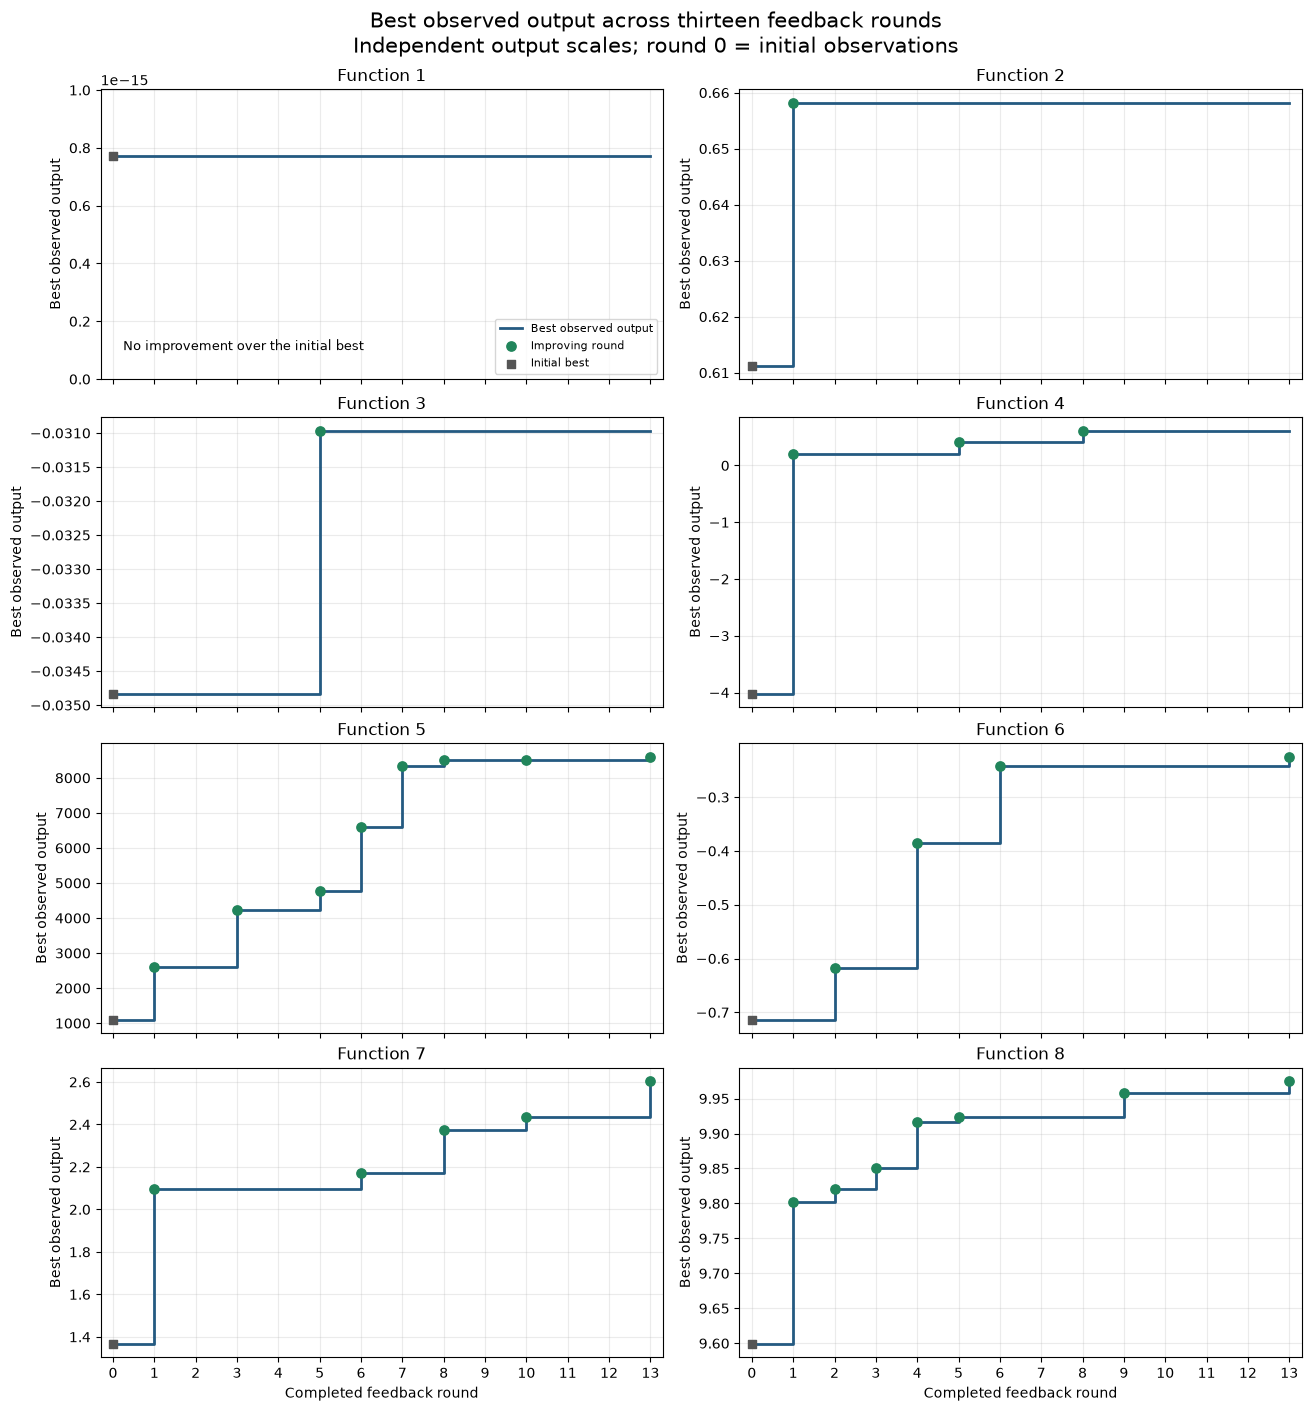

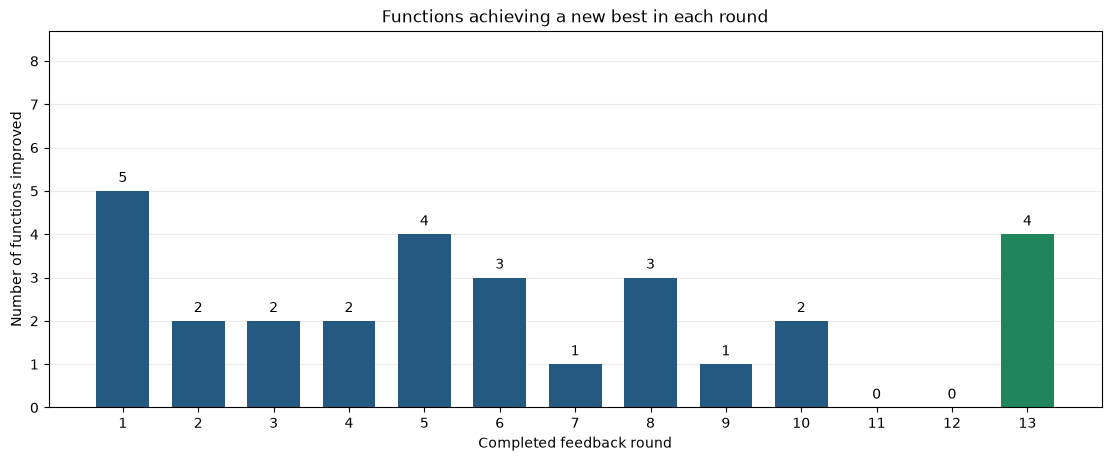

Round 0 represents the supplied initial observations.
Each function's best-so-far curve uses its own output scale.
Improvement counts do not measure improvement magnitude.
These charts are not aggregate leaderboard scores.
Figures remain available in memory for later export.


In [5]:
# CP_25 — Final evaluation
# Plot best-so-far histories and the number of improvements per round.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, ScalarFormatter

required_variables = [
    "best_so_far_history_df",
    "round_improvement_summary_df",
    "completed_rounds",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the progress-summary cell first. Missing variables: "
        + ", ".join(missing_variables)
    )

round_ticks = np.arange(completed_rounds + 1)

# Separate panels preserve each function's original output units.
fig_best_so_far, axes = plt.subplots(
    4,
    2,
    figsize=(13, 14),
    sharex=True,
    constrained_layout=True,
)

for function_id, ax in zip(range(1, 9), axes.flat):
    history = (
        best_so_far_history_df.loc[
            best_so_far_history_df["Function"] == function_id
        ]
        .sort_values("Round")
    )

    rounds = history["Round"].to_numpy(dtype=int)
    best_values = history["Best observed output"].to_numpy(dtype=float)
    improving = history["Improved"].to_numpy(dtype=bool)

    if not np.array_equal(rounds, round_ticks):
        raise ValueError(
            f"Function {function_id}: incomplete round history."
        )

    if np.any(np.diff(best_values) < 0):
        raise ValueError(
            f"Function {function_id}: best-so-far values decreased."
        )

    ax.step(
        rounds,
        best_values,
        where="post",
        color="#245A81",
        linewidth=2,
        label="Best observed output",
    )

    ax.scatter(
        rounds[improving],
        best_values[improving],
        color="#21855B",
        s=45,
        zorder=3,
        label="Improving round",
    )

    ax.scatter(
        [0],
        [best_values[0]],
        color="#555555",
        marker="s",
        s=40,
        zorder=3,
        label="Initial best",
    )

    ax.set_title(f"Function {function_id}")
    ax.set_ylabel("Best observed output")
    ax.set_xticks(round_ticks)
    ax.set_xlim(-0.3, completed_rounds + 0.3)
    ax.grid(True, alpha=0.25)

    formatter = ScalarFormatter(useOffset=False)
    formatter.set_powerlimits((-3, 4))
    ax.yaxis.set_major_formatter(formatter)

    if function_id == 1:
        # A zero-based axis avoids magnifying a constant near-zero value.
        ax.set_ylim(0, best_values[0] * 1.3)
        ax.text(
            0.04,
            0.10,
            "No improvement over the initial best",
            transform=ax.transAxes,
            fontsize=9,
        )

for ax in axes[-1, :]:
    ax.set_xlabel("Completed feedback round")

axes[0, 0].legend(loc="lower right", fontsize=8)

fig_best_so_far.suptitle(
    "Best observed output across thirteen feedback rounds\n"
    "Independent output scales; round 0 = initial observations",
    fontsize=15,
)

plt.show()

# Count strict improvements separately from their numerical magnitudes.
round_summary = round_improvement_summary_df.sort_index()
feedback_rounds = round_summary.index.to_numpy(dtype=int)
improvement_counts = round_summary["Count"].to_numpy(dtype=int)

if not np.array_equal(
    feedback_rounds,
    np.arange(1, completed_rounds + 1),
):
    raise ValueError("The round-improvement summary is incomplete.")

fig_improvement_counts, ax = plt.subplots(
    figsize=(11, 4.5),
    constrained_layout=True,
)

colours = [
    "#21855B" if round_number == completed_rounds else "#245A81"
    for round_number in feedback_rounds
]

bars = ax.bar(
    feedback_rounds,
    improvement_counts,
    color=colours,
    width=0.7,
)

ax.bar_label(bars, padding=4)
ax.set_xticks(feedback_rounds)
ax.set_ylim(0, 8.7)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Completed feedback round")
ax.set_ylabel("Number of functions improved")
ax.set_title("Functions achieving a new best in each round")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.show()

print("Round 0 represents the supplied initial observations.")
print("Each function's best-so-far curve uses its own output scale.")
print("Improvement counts do not measure improvement magnitude.")
print("These charts are not aggregate leaderboard scores.")
print("Figures remain available in memory for later export.")

## 6. Interpret the final results

I completed thirteen feedback rounds, adding 104 evaluations to the
175 supplied observations. Seven of the eight functions improved over
their initial best.

Progress differed across functions. Function 2 achieved its best result
in round 1, Function 3 in round 5 and Function 4 in round 8. Function 1
never improved over its initial best. These plateaus do not establish
that the global optima were reached.

Function 5 improved in eight rounds, while Functions 6, 7 and 8 also
achieved new best outputs in the final round. After no improvements in
rounds 11 and 12, round 13 improved four functions.

For the final submission, I selected the highest predicted mean among
the eligible candidates rather than adding an uncertainty bonus.
Global and local candidate searches remained available. For Function 5,
I removed the additional minimum-distance constraint of 0.01 while
retaining the general duplicate tolerance.

The final results support this decision at the selected points, but
they do not prove that this policy was superior to the alternatives:
the other proposed points were not evaluated.

Prediction accuracy and optimisation success also differed. Function 6
improved despite a predicted mean below its previous best. Function 7
achieved a new best, but its prediction error was approximately 3.55
times the predicted standard deviation. Function 5's GP prediction was
closer to the final output than its auxiliary neural-network prediction.

My main conclusion is that useful optimisation requires both tracking
observed improvements and checking the reliability of the predictions
guiding decisions. A successful query does not, by itself, validate the
model's uncertainty estimates.

## 7. Export the final evaluation

I save the validated observations, performance summaries, historical
predictions and figures under `results/final_evaluation/`.

The observation export preserves numerical coordinates as JSON lists.
Round 0 identifies supplied initial observations; rounds 1–13 identify
portal feedback. Predictions are saved separately from observations.

These exports support the final README, datasheet, model card and
retrospective. Rerunning this cell replaces the generated exports in
this folder without changing the source data or historical notebooks.

In [6]:
# CP_25 — Final evaluation
# Export final results and figures for documentation and review.

import json
from pathlib import Path

import numpy as np
import pandas as pd

required_variables = [
    "project_path",
    "completed_rounds",
    "initial_data",
    "feedback_data",
    "data_validation_df",
    "final_round_results_df",
    "overall_progress_df",
    "best_observed_points_df",
    "best_so_far_history_df",
    "round_improvement_summary_df",
    "historical_round13",
    "final_prediction_errors_df",
    "fig_best_so_far",
    "fig_improvement_counts",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the preceding cells first. Missing variables: "
        + ", ".join(missing_variables)
    )

export_path = Path(project_path) / "results" / "final_evaluation"
export_path.mkdir(parents=True, exist_ok=True)

observation_records = []

for function_id in range(1, 9):
    initial = initial_data[function_id]
    feedback = feedback_data[function_id]

    for observation_index, (coordinates, output) in enumerate(
        zip(initial["X"], initial["y"]),
        start=1,
    ):
        observation_records.append({
            "Function": function_id,
            "Round": 0,
            "Source": "Initial data",
            "Observation within function": observation_index,
            "inputs_json": json.dumps(
                np.asarray(coordinates, dtype=float).tolist(),
                allow_nan=False,
            ),
            "Observed output": float(output),
        })

    for round_number, (coordinates, output) in enumerate(
        zip(feedback["X"], feedback["y"]),
        start=1,
    ):
        observation_records.append({
            "Function": function_id,
            "Round": round_number,
            "Source": "Portal feedback",
            "Observation within function": (
                len(initial["y"]) + round_number
            ),
            "inputs_json": json.dumps(
                np.asarray(coordinates, dtype=float).tolist(),
                allow_nan=False,
            ),
            "Observed output": float(output),
        })

final_observations_df = pd.DataFrame(observation_records)

if len(final_observations_df) != 279:
    raise ValueError(
        f"Expected 279 observations, found {len(final_observations_df)}."
    )

# Use JSON for the list-valued column to make the CSV easy to parse.
round_summary_export = round_improvement_summary_df.copy()
round_summary_export["Improved functions"] = (
    round_summary_export["Improved functions"].apply(json.dumps)
)

tables_to_export = {
    "observations.csv": final_observations_df,
    "data_validation.csv": data_validation_df.reset_index(),
    "round13_results.csv": final_round_results_df.reset_index(),
    "overall_progress.csv": overall_progress_df.reset_index(),
    "best_observed_points.csv": best_observed_points_df.reset_index(),
    "best_so_far_history.csv": best_so_far_history_df,
    "round_improvement_summary.csv": round_summary_export.reset_index(),
    "round13_historical_predictions.csv": historical_round13.reset_index(),
    "round13_prediction_errors.csv": final_prediction_errors_df.reset_index(),
}

exported_files = []

for filename, dataframe in tables_to_export.items():
    destination = export_path / filename

    dataframe.to_csv(
        destination,
        index=False,
        encoding="utf-8",
        float_format="%.17g",
        na_rep="",
    )

    exported_files.append(destination)

figures_to_export = {
    "best_so_far": fig_best_so_far,
    "improvement_counts": fig_improvement_counts,
}

for filename, figure in figures_to_export.items():
    for extension in ["png", "pdf"]:
        destination = export_path / f"{filename}.{extension}"

        figure.savefig(
            destination,
            dpi=200,
            bbox_inches="tight",
            facecolor="white",
        )

        exported_files.append(destination)

metadata = {
    "notebook": "CP_25.ipynb",
    "stage": "Final evaluation; no further queries",
    "completed_feedback_rounds": int(completed_rounds),
    "initial_observations": int(
        sum(len(data["y"]) for data in initial_data.values())
    ),
    "feedback_observations": int(
        sum(len(data["y"]) for data in feedback_data.values())
    ),
    "total_observations": int(len(final_observations_df)),
    "prediction_source": "Rounded historical predictions recorded in CP_24",
    "models_refitted_for_prediction_comparison": False,
    "notes": [
        "Round 0 identifies supplied initial observations.",
        "Predictions are stored separately from observed outputs.",
        "Blank auxiliary predictions mean no auxiliary model was used.",
        "Blank round-0 feedback fields are not missing function evaluations.",
        "Best-point coordinate strings are rounded to six decimals.",
        "Observation coordinates are preserved as numerical JSON lists.",
        "Raw improvements are not comparable across functions.",
        "These exports do not contain an aggregate leaderboard score.",
    ],
}

metadata_path = export_path / "evaluation_metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2, allow_nan=False) + "\n",
    encoding="utf-8",
)
exported_files.append(metadata_path)

for file_path in exported_files:
    if not file_path.is_file() or file_path.stat().st_size == 0:
        raise RuntimeError(f"Export failed: {file_path}")

print("Final evaluation exports saved to:")
print(export_path)

print("\nGenerated files:")
for file_path in exported_files:
    print(f"- {file_path.name}")

print(f"\nTotal files exported: {len(exported_files)}")
print("Source data and historical notebooks were not modified.")

Final evaluation exports saved to:
C:\Users\AG\BeatrizGIT\Master\CapstoneProject\results\final_evaluation

Generated files:
- observations.csv
- data_validation.csv
- round13_results.csv
- overall_progress.csv
- best_observed_points.csv
- best_so_far_history.csv
- round_improvement_summary.csv
- round13_historical_predictions.csv
- round13_prediction_errors.csv
- best_so_far.png
- best_so_far.pdf
- improvement_counts.png
- improvement_counts.pdf
- evaluation_metadata.json

Total files exported: 14
Source data and historical notebooks were not modified.
